In [5]:
# 基础库
import numpy as np
import xarray as xr
import pandas as pd
import os
import sys
import gc  
import pickle

# 统计分析库
import statsmodels.api as sm
from scipy.stats import norm, ttest_1samp
import pymannkendall as mk
from scipy.stats import pearsonr
from scipy.stats import linregress

# 地理空间处理库
from shapely.geometry import Point
import geopandas as gpd

# 并行处理库
from multiprocessing import Pool, cpu_count

# 可视化库
from matplotlib import gridspec, pyplot as plt
from matplotlib.lines import Line2D
from cartopy import crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import matplotlib.path as mpath
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

# 自定义模块
sys.path.append('/public/home/zhujw/work/guoly/code/Self-package/ccg_filter')
import ccg_filter

def mk_test(x):
    ## mk检验，输入时间序列W后，输出对应的标准正态值
    S = 0
    n = len(x)
    for i in range(n - 1):
        for j in range(i + 1, n):
            S += np.sign(x[j] - x[i])
    data_sort = np.sort(x)
    num = 0
    nn = 0
    for i in range(len(x) - 1):
        if data_sort[i + 1] - data_sort[i] <= 1.0e-37:
            nn += 1
        else:
            num += nn * (nn - 1) * (2 * nn + 5)
            nn = 1
    var_s = (n * (n - 1) * (2 * n + 5) - num) / 18
    if S > 0:
        Z = (S - 1) / np.sqrt(var_s)
    elif S == 0:
        Z = 0
    elif S < 0:
        Z = (S + 1) / np.sqrt(var_s)

    return Z

def trend_window(AMP, min_line, cal_type=None, mk_type=None):
#    这个函数用来计算AMP的滑动窗口趋势，或者非滑动窗口趋势
#    AMP 原始序列 min_line 滑动窗口最小数 
#    当cal_type不为空时，使用gls方法计算b
    b = []
    p = []
    x = np.arange(1, len(AMP) + 1)
    line_start = x[:len(x) - min_line + 1]
    for i in range(len(line_start)):
        AMP_now = AMP[i:i + min_line]
        x_now = np.arange(1, min_line + 1)

        if cal_type is not None:
            x_now = sm.add_constant(x_now)
            gls_model = sm.GLS(AMP_now, x_now)
            gls_results = gls_model.fit()
            params = gls_results.params
            b.append(params[1])
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
        
        else:
            b0 = np.polyfit(x_now[~np.isnan(AMP_now)], AMP_now[~np.isnan(AMP_now)], 1)  # min_square的系数
            if mk_type is not None:
                p.append(1 - norm.cdf(mk_test(AMP_now[~np.isnan(AMP_now)]), 0, 1))
            else:
                result = mk.original_test(AMP_now)
                p.append(result.p)
            b.append(b0[0])

    Z = np.vstack((p, b))
    return Z

def cal_trend_diff(data, time, min_len, trend_select, p_threshold=0.1, site=None, ratio_flag=None):
    """
    计算数据的heatmap和时间映射

    Parameters:
    data : 一维数组，原始数据
    time : 一维数组，时间序列
    min_len : int，最小窗口长度，用于计算趋势
    trend_select : int，选取计算趋势差的窗口长度
    ratio_flag : True/False，是否返回趋势差的比值形式

    Returns:
    diff : 一维数组，包含趋势差
    sign_start : int，趋势开始的符号
    """
    len_amp = len(data)

    # 初始化 heat_map 和 time_map ([p, b], start_time, end_time)
    heat_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)
    time_map = np.full((2, len_amp - min_len, len_amp - min_len), np.nan)

    # 计算趋势的 heat_map 和时间映射
    for i in range(len_amp - min_len):
        for j in range(i + min_len, len_amp):
            # # 1) 只保留「前 trend_select 行」和「最后 trend_select 行」
            # if i > trend_select and i < (len_amp - trend_select - min_len):
            #     continue
            # # 2) 只保留「窗口长度 <= trend_select」的对角线附近区域
            # if (j - i - min_len) > trend_select:
            #     continue
            amp_now = data[i:j]
            trend_result = trend_window(amp_now, j - i, cal_type=0, mk_type=1).squeeze()
            heat_map[:, i, j - min_len] = trend_result
            time_map[:, i, j - min_len] = [time[i], time[j]]

    # 计算趋势差 diff
    trend_start = heat_map[1, :trend_select, :trend_select]
    trend_end = heat_map[1, -trend_select:, -trend_select:]
    diff = trend_end - trend_start
    diff = diff[~np.isnan(diff)]
    print(f"Trend start: {np.nanmean(trend_start)*1000:.3f} \u00B1 {np.nanstd(trend_start)*1000:.3f} \n"
          f"Trend end: {np.nanmean(trend_end)*1000:.3f} \u00B1 {np.nanstd(trend_end)*1000:.3f} \n"
          f"Trend diff: {np.nanmean(diff)*1000:.3f} \u00B1 {np.nanstd(diff)*1000:.3f}")

    # 计算显著性
    t, p_diff = ttest_1samp(diff.flatten(), popmean=0, nan_policy='omit')
    diff_mean = np.nanmean(diff)
    t_stat, p_start = ttest_1samp(trend_start.flatten(), popmean=0, nan_policy='omit')
    start_mean = np.nanmean(trend_start)
    t_end, p_end = ttest_1samp(trend_end.flatten(), popmean=0, nan_policy='omit')
    end_mean = np.nanmean(trend_end)

    if (p_diff > p_threshold) or (diff_mean == 0):
        sign = -1
    else:
        if diff_mean >= 0:
            if start_mean >= 0 and end_mean > 0: sign = 1
            elif start_mean <= 0 and end_mean >= 0: sign = 2
            elif start_mean < 0 and end_mean <= 0: sign = 3
        elif diff_mean < 0:
            if start_mean > 0 and end_mean >= 0: sign = 4
            elif start_mean >= 0 and end_mean <= 0: sign = 5
            elif start_mean <= 0 and end_mean < 0: sign = 6

    if ratio_flag:
        ratio = trend_end / trend_start
        ratio = ratio[~np.isnan(ratio)]
        return diff, sign, p_diff, ratio, heat_map, time_map
    else:
        return diff, sign, p_diff, heat_map, time_map

def p_to_stars(p):
    if p <= 0.001:
        return '***'
    elif p <= 0.05:
        return '**'
    elif p <= 0.1:
        return '*'
    else:
        return ''

def process_trend_diff(args):
    """
    并行处理趋势差异计算的函数。
    """
    data, time, min_line, trend_select = args
    return cal_trend_diff(data, time, min_line, trend_select)

def cal_area_grid(lat, lon, radius=6371000):
    lat_rad = np.radians(lat)
    lat_diff = np.diff(lat_rad) / 2  # 使用中间差值
    
    area = np.zeros((len(lat), len(lon)))
    
    lat_area_factors = radius ** 2 * np.abs(
        np.sin(lat_rad[:-1] + lat_diff) - np.sin(lat_rad[:-1] - lat_diff)
    )

    lon_diff = np.abs(np.radians(lon[1] - lon[0]))

    area[:-1, :] = lat_area_factors[:, np.newaxis] * lon_diff
    area[-1, :] = area[-2, :] 
    area[:, -1] = area[:, -2] 
    
    return area

def is_leap_year(year): # 判断是否为闰年
    if year % 4 == 0:
        if year % 100 == 0:
            if year % 400 == 0:
                return True
            else:
                return False
        else:
            return True
    else:
        return False

def days_in_month(year, month): # 获取指定年份和月份的天数
    if month in [1, 3, 5, 7, 8, 10, 12]:
        return 31
    elif month in [4, 6, 9, 11]:
        return 30
    elif month == 2:
        if is_leap_year(year):
            return 29
        else:
            return 28
    else:
        return None

def day_of_year(year, month, day): # 获取指定日期在一年中的第几天
    total_days = 0
    for m in range(1, month):
        total_days += days_in_month(year, m)
    total_days += day
    return total_days
    
def time_to_decimal(time):
    if time.shape[0] == 2:
        time = np.vstack((time, np.ones((1, time.shape[1]))*15))
    years = np.squeeze(time[0, :]).astype(int)
    months = np.squeeze(time[1, :]).astype(int)
    days = np.squeeze(time[2, :]).astype(int)
    time_decimal = np.full(len(years), np.nan)
    for i, (year, month, day) in enumerate(zip(years, months, days)):
        day_of_year_value = day_of_year(year, month, day)
        if is_leap_year(year):
            time_decimal[i] = day_of_year_value / 366 + year
        else:
            time_decimal[i] = day_of_year_value / 365 + year
    return time_decimal

def smooth_cycle_cal(time, data, period):

    filt = ccg_filter.ccgFilter(time, data)
    start_time = np.floor(time[0]).astype(int)
    end_time = np.ceil(time[-1]).astype(int)
    all_dates = []
    for year in range(start_time, end_time + 1):
        yearly_dates = pd.date_range(start=f'{year}-01-01', end=f'{year}-12-31', periods=period)
        all_dates.extend(yearly_dates)
    year = [date.year for date in all_dates]
    month = [date.month for date in all_dates]
    day = [date.day for date in all_dates]
    date_array = np.vstack([year, month, day])
    time = time_to_decimal(date_array)

    trend = filt.getTrendValue(time)
    smooth =  filt.getSmoothValue(time)
    # harmonics = filt.getHarmonicValue(time)
    smooth_cycle =  smooth - trend

    return smooth_cycle, time

def calculate_amplitude_cycle(time, data, lat_num, period):
    """计算给定数据的振幅和季节循环
    
    Args:
        time (array): 时间序列
        data (array): 待处理的数据，shape为(lat_num, time)
        lat_num (int): 纬度区域数量
    
    Returns:
        amp (array): 振幅数据，shape为(lat_num, years)
        cycle (array): 季节循环数据，shape为(lat_num, 12)
        time_cycle (array): 季节循环对应的时间
        time_amp (array): 振幅对应的时间
    """
    filt = ccg_filter.ccgFilter(time, data[0, :])

    # 初始化输出数组
    amp = np.full((lat_num, np.array(filt.getAmplitudes()).shape[0]), np.nan)
    cycle = []
    
    # 遍历每个纬度带
    for i in range(lat_num):
        # 计算振幅
        filt = ccg_filter.ccgFilter(time, data[i, :])
        amps = filt.getAmplitudes()
        amp[i, :] = np.array(amps)[:, 1]
        time_amp = np.array(amps)[:, 0]
        
        # 计算季节循环
        cycle_now, time_cycle = smooth_cycle_cal(time, data[i, :], period)
        if len(cycle) == 0:
            cycle = cycle_now
        else:
            cycle = np.vstack((cycle, cycle_now))
    
    return amp, cycle, time_cycle, time_amp

def add_amplitude_annotation(ax, data, period_len, amp_label='Amplitude'):
    """自动在曲线上标注 Max, Min 以及振幅双向箭头"""
    max_idx = np.nanargmax(data)
    min_idx = np.nanargmin(data)
    max_val = data[max_idx]
    min_val = data[min_idx]
    ylim_range = max_val - min_val
    
    # 极值文本标注
    ax.text(max_idx, max_val - ylim_range * 0.02, 'Peak', 
            color='#d62828', fontsize=9, fontweight='bold', ha='center', va='top')
    ax.text(min_idx, min_val - ylim_range * 0.02, 'Trough', 
            color='#0077b6', fontsize=9, fontweight='bold', ha='center', va='top')
    
    # 极值点向下垂线
    # ax.vlines(max_idx, 0, max_val, color='#d62828', linestyle='--', linewidth=1.5, alpha=0.6)
    # ax.vlines(min_idx, 0, min_val, color='#0077b6', linestyle='--', linewidth=1.5, alpha=0.6)
    
    # 振幅标示线和双向箭头
    off1, off_mid = period_len * 0.09, period_len * 0.06
    ax.hlines(max_val, max_idx - off1, max_idx, color='black', linestyle='--', linewidth=1)
    ax.hlines(min_val, max_idx - off1, min_idx, color='black', linestyle='--', linewidth=1)
    
    ax.annotate('', xy=(max_idx - off_mid, max_val), xytext=(max_idx - off_mid, min_val),
                arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
    
    ax.text(max_idx - off_mid - period_len * 0.02, (max_val + min_val) / 2, amp_label,
            rotation=90, ha='center', va='center', fontsize=10, fontweight='bold', color='black')

In [6]:
## Decomposition结果和LGR
area_idx = 0
with open(f'/public/home/zhujw/work/guoly/code/Paper-1-global/code-fig/data-pre/fig3/fig3-result_dict_25.pkl', 'rb') as f:
    result_dict = pickle.load(f)

part1_dict = {}

for num_model, (model, info) in enumerate(result_dict.items()):
    alpha_value = np.flip(info['alpha_value'], axis=(0))[area_idx]
    beta_value_zscore = np.flip(info['beta_value_zscore'], axis=(1))[:, area_idx]
    GR_value = np.flip(info['GR_value'], axis=(1))[:, area_idx]
    land_contribution = alpha_value * GR_value[1] * beta_value_zscore[1]
    ocean_contribution = alpha_value * GR_value[0] * beta_value_zscore[0]
    if model == 'Multi-model':
        model = 'Trendy'
    part1_dict[model] = {
        'l_contri': land_contribution if model == 'Jena' else land_contribution[2:],
        'o_contri': ocean_contribution if model == 'Jena' else ocean_contribution[2:],
        'time': np.arange(1981, 2022),
        'mbl_trend': GR_value[2, 2:],
        'lgr': GR_value[1, 2:]
    }
    
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/each/'
files = os.listdir(folder)
for file in files:
    model = file.split('.')[0]
    with xr.open_dataset(folder + file) as ds:
        amp_cum_region = ds['amp_cum_region'].values[-1]
        part1_dict[model]['amp_cum'] = amp_cum_region

files = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/ensemble/data.nc'
with xr.open_dataset(files) as ds:
    amp_cum_region = ds['amp_cum_region'].values[-1]
    
    # 提取前三个模型，向后截取最后41年(1981-2021)对齐后求平均
    first_3_models = list(part1_dict.keys())[:3]
    l_contri_multi = np.mean([part1_dict[m]['l_contri'][-17:] for m in first_3_models], axis=0)
    o_contri_multi = np.mean([part1_dict[m]['o_contri'][-17:] for m in first_3_models], axis=0)
    
    part1_dict['Multi-model'] = {
        'amp_cum': amp_cum_region,
        'time': np.arange(1981, 2022),
        'l_contri': l_contri_multi,
        'o_contri': o_contri_multi,
        'mbl_trend': part1_dict['CAMS']['mbl_trend'],
    }


In [7]:
part2_dict = {}
min_len = 20
trend_select = 7
count_diff = int(np.sum(np.arange(1, trend_select + 1)))

# ==========================================
# 收集所有文件（individual + ensemble）
# ==========================================
folder = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/each/'
file_multi = '/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/data/amp-cum-control/ensemble/data.nc'

files_to_process = [(os.path.join(folder, f), f.split('.')[0]) for f in os.listdir(folder)]
files_to_process.append((file_multi, 'Ensemble'))

# ==========================================
# 统一处理所有模型
# ==========================================
for file_path, model in files_to_process:
    with xr.open_dataset(file_path) as ds:
        amp_region = ds['amp_cum_region'].values
        time = ds['time'].values
        
        valid_idx = (time >= 1981) & (time <= 2021)
        amp_region = amp_region[-1, valid_idx]  # 只取最后一个region
        time = time[valid_idx]
        print(model, amp_region, '\n')
        
        # 初始化模型数据
        part2_dict[model] = {
            'amp_region': amp_region,
            'time': time,
            'diff_region': np.full((count_diff), np.nan),
            'sign_region': np.nan,
            'p_diff_region': np.nan
        }
    
    print(f"Processing model: {model}")
    # 计算趋势差异
    diff_region, sign_region, p_diff_region, r, _, _ = cal_trend_diff(
        part2_dict[model]['amp_region'], part2_dict[model]['time'], min_len, trend_select, ratio_flag=True
    )
    print(np.nanmean(r-1)*100, np.nanstd(r-1)*100)
    part2_dict[model]['diff_region'] = diff_region
    part2_dict[model]['sign_region'] = sign_region
    part2_dict[model]['p_diff_region'] = p_diff_region

Jena [2.84959673 2.71812901 2.61677179 2.65654742 2.7716006  2.58792914
 2.6918831  2.76793082 2.70134093 2.82634995 2.88746741 2.87571984
 2.94373064 2.82833074 2.77106577 2.6718231  2.85155721 2.73647844
 2.83105641 2.79084543 2.97742985 2.76934114 2.8206846  3.04205179
 3.26331035 2.94603316 3.01892113 2.92037042 3.08284825 2.94158696
 3.13141755 2.96979251 3.16973364 2.84052127 3.04467113 3.22026463
 2.9877142  2.98466279 3.23400937 2.92884502 3.03578328] 

Processing model: Jena
Trend start: 10.825 ± 2.739 
Trend end: 13.291 ± 2.507 
Trend diff: 2.466 ± 4.713
36.12236270902115 57.72597525862506
Trendy [2.66820997 2.67384332 2.72681062 2.72939067 2.76313318 2.7598671
 2.74127884 2.74083527 2.82494757 3.01044623 2.89274637 2.82297446
 2.9783398  2.89682372 2.90799924 2.79034398 2.95553467 2.81348748
 2.8998838  3.07606723 3.08685693 2.9601135  3.00585192 3.03102355
 3.2473289  3.10265412 3.13302686 3.12917842 3.20743594 3.07172645
 3.26512528 3.15580902 3.28798536 3.23314431 3.27611

In [8]:
# =========================================================
# 读取 CO2 数据
# =========================================================
period = 180
file_path = '/public/home/zhujw/work/guoly/data/CO2/NOAA-zonal/Area-NH/co2_NH_boreal_zonal.txt'

mbl_data = []
mbl_time = None
data_now = np.array([], dtype=np.float64)

with open(file_path, 'r') as f:
    lines = f.readlines()
    for line in lines[71:]:
        parts = line.strip().split()[3:5]
        float_parts = [np.float64(part) for part in parts]
        if len(data_now) == 0:
            data_now = np.array([float_parts])
        else:
            data_now = np.vstack((data_now, float_parts))

mbl_time = data_now[:, 0]
mbl_data = data_now[:, 1].reshape(1, -1)

# 计算 CO2 振幅和循环
amp_zonal, cycle, time_co2, time_SCA = calculate_amplitude_cycle(
    time=mbl_time,
    data=mbl_data,
    lat_num=1,
    period=period
)

# =========================================================
# 读取 Multi-model 数据
# =========================================================
folder_path = '/public/home/zhujw/work/guoly/code/Paper-1-global/code-fig/data-pre/Carbon-flux/'
files = os.listdir(folder_path)
nc_files = [file for file in files if file.endswith('.nc')]

# 找到 Multi-model 文件
multi_model_file = [f for f in nc_files if 'Multi-model' in f or 'multi-model' in f.lower()][0]
ds = xr.open_dataset(os.path.join(folder_path, multi_model_file))

land_flux = ds['land_flux'].values
time_flux = ds['time_flux'].values

start_time = 1982
end_time = 2022

# 处理 Boreal 区域（-1）
smooth_temp, time_cycle = smooth_cycle_cal(time_flux, land_flux[-1], period)
smooth_cycle = np.nancumsum(smooth_temp)[np.where((time_cycle >= start_time) & (time_cycle < end_time))[0]].reshape(end_time - start_time, period)
annual_cum = np.nanmean(smooth_cycle, axis=0) / period

smooth_temp, time_cycle = smooth_cycle_cal(time_flux, land_flux[-1], period)
smooth_cycle = smooth_temp[np.where((time_cycle >= start_time) & (time_cycle < end_time))[0]].reshape(end_time - start_time, period)
annual_flux = np.nanmean(smooth_cycle, axis=0)

annual_co2 = cycle[np.where((time_cycle >= start_time) & (time_cycle < end_time))[0]] \
             .reshape(end_time - start_time, period).mean(axis=0)

2.2312845623121245 1.4140348841841177
CAMS: Slope=0.00418 P-value=9.212e-09 Stars=***
Trendy: Slope=0.00368 P-value=9.212e-09 Stars=***
Jena: Slope=0.00121 P-value=9.212e-09 Stars=***
Ensemble: Slope=0.00302 P-value=9.212e-09 Stars=***
MBL: Slope=0.00546 P-value=9.212e-09 Stars=***


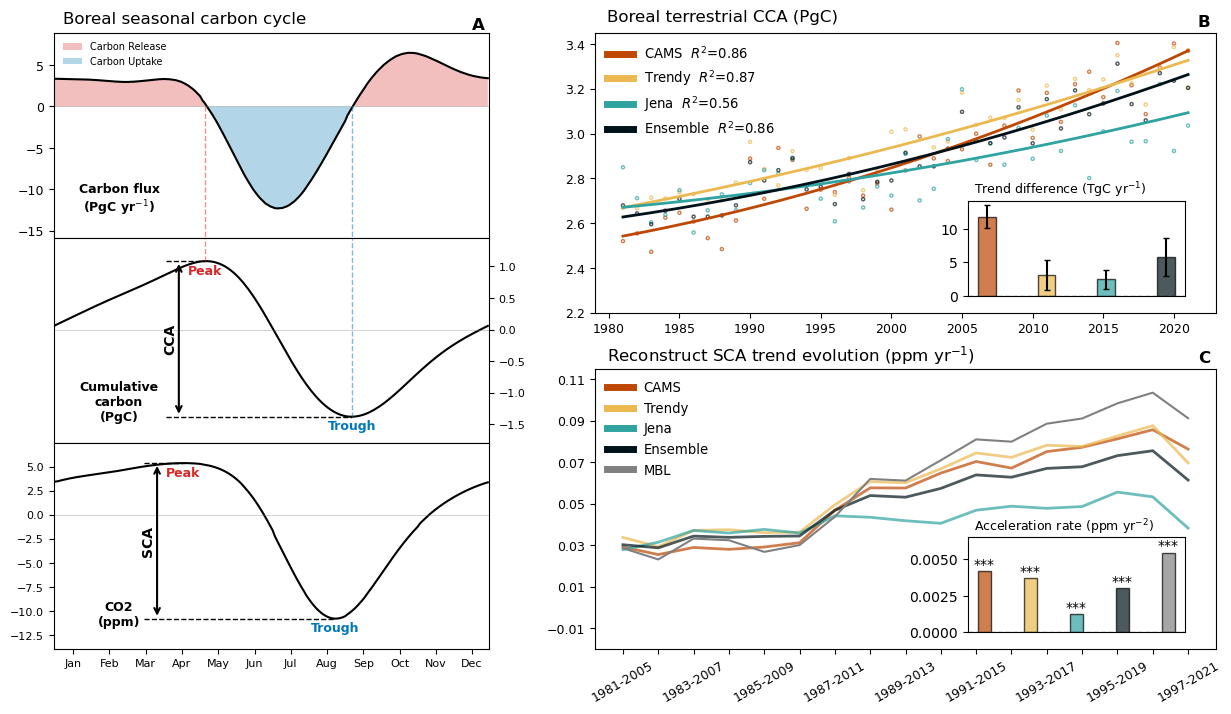

In [ ]:
# region Part 0: 绘图配置和初始化
# ==========================================
# 绘图配置参数（统一管理）
# ==========================================
PLOT_CONFIG = {
    'figsize': (15, 8),
    'nrows': 2,
    'ncols': 2,
    'hspace': 0.2,
    'wspace': 0.2,
    'alpha': 0.7,
    'color_map': ['#001219', '#005f73', '#0a9396', '#94d2bd', '#e9d8a6',
                  '#ee9b00', '#ca6702', '#bb3e03', '#ae2012', '#9b2226'],
    'model_list': ['CAMS', 'Trendy', 'Jena', 'Ensemble'],
}

# ==========================================
# 初始化颜色和图表
# ==========================================
cm_custom = LinearSegmentedColormap.from_list('custom', PLOT_CONFIG['color_map'])
color_list = [cm_custom(i / 4) for i in range(4)][::-1]

# 主 GridSpec：2行2列，左窄右宽
gs = gridspec.GridSpec(PLOT_CONFIG['nrows'], 2,
                       width_ratios=[0.7, 1],
                       height_ratios=[1, 1],
                       wspace=PLOT_CONFIG['wspace'],
                       hspace=PLOT_CONFIG['hspace'])

fig = plt.figure(figsize=PLOT_CONFIG['figsize'])

# 左侧：拆成 3 行（Flux / CCA / CO2 各占 1/3）
gs_left = gridspec.GridSpecFromSubplotSpec(3, 1, subplot_spec=gs[:, 0], hspace=0.0)
ax_flux  = fig.add_subplot(gs_left[0])
ax_cum   = fig.add_subplot(gs_left[1])
ax_co2   = fig.add_subplot(gs_left[2])

# 右侧：保持原样
ax_right_top    = fig.add_subplot(gs[0, 1:])
ax_right_bottom = fig.add_subplot(gs[1, 1:])

axs = [ax_flux, ax_right_top, ax_right_bottom]        # 旧索引兼容
axs_left = [ax_flux, ax_cum, ax_co2]                   # 左侧三子图

# endregion

# region Part 1: 陆地碳循环加速
# ==========================================
# Part 1: 绘制主图 - 陆地碳循环加速
# ==========================================
ax = axs[1]
new_labels = []
diff_mean = []
diff_std = []

for num_model, model in enumerate(PLOT_CONFIG['model_list']):
    # 获取数据
    info = part2_dict[model]
    amp = info['amp_region']
    time = info['time']
    
    # 拟合和计算 R2
    p = np.polyfit(t_rel, amp, 2)
    amp_fitted = np.polyval(p, t_rel)
    ss_res = np.sum((amp - amp_fitted) ** 2)
    ss_tot = np.sum((amp - np.mean(amp)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    new_labels.append(f'{model}  $R^2$={r2:.2f}')
    
    # 绘制散点和拟合线
    t_fit = np.linspace(t_rel.min(), t_rel.max(), 200)
    amp_fit = np.polyval(p, t_fit)
    time_fit = t_fit + t0
    
    ax.scatter(time, amp, color=color_list[num_model], facecolors='none', s=5, alpha=PLOT_CONFIG['alpha'])
    ax.plot(time_fit, amp_fit, color=color_list[num_model], linewidth=2, zorder=3)
    
    # 计算差值统计
    diff_region = np.asarray(part2_dict[model]['diff_region'])
    diff_region = diff_region[~np.isnan(diff_region)]
    diff_mean.append(np.mean(diff_region * 1000))
    diff_std.append(np.std(diff_region * 1000))


# 绘制图例
custom_lines = [Line2D([0], [0], color=color_list[i], lw=5) for i in range(len(PLOT_CONFIG['model_list']))]
ax.legend(custom_lines, new_labels, fontsize=9.5, loc='upper left', frameon=False)
# ax.set_yticklabels([f'{v:.1f}' for v in ax.get_yticks()], fontsize=8)
ax.text(0.02, 1.03, 'Boreal terrestrial CCA (PgC)', fontsize=12, ha='left', va='bottom', transform=ax.transAxes)
ax.set_ylim(2.2, 3.45)

# 内嵌柱状图
ax_inset = inset_axes(ax, width="100%", height="100%",
                      bbox_to_anchor=(0.6, 0.06, 0.35, 0.34),
                      bbox_transform=ax.transAxes, borderpad=0.0)
ax_inset.bar(range(len(PLOT_CONFIG['model_list'])), diff_mean, yerr=diff_std,
             color=color_list, alpha=0.7, capsize=2, width=0.3, edgecolor='k')
ax_inset.axhline(0, color='gray', linestyle='--', linewidth=1)
ax_inset.text(0.03, 1.01, 'Trend difference (TgC yr$^{-1})$', fontsize=9, ha='left', va='bottom', transform=ax_inset.transAxes)
ax_inset.set_xticks([])
# endregion

# region Part 2: 大气CO2趋势
# ==========================================
# Part 2: 绘制趋势演变 - 大气CO2
# ==========================================
ax = axs[2]
x = np.arange(2022 - 41 + (25 - 1) / 2, 2022 - (25 - 1) / 2)
slope_list = []
stars_list = []

for i, model in enumerate(PLOT_CONFIG['model_list']):
    model_key = 'Multi-model' if model == 'Ensemble' else model
    land_contribution = part1_dict[model_key]['l_contri']
    ocean_contribution = part1_dict[model_key]['o_contri']
    x_seg = x[-len(land_contribution):]
    y = np.asarray(land_contribution + ocean_contribution)
    
    res = linregress(x_seg, y)
    slope, pval = res.slope, res.pvalue
    y_fit = res.intercept + slope * x_seg
    stars = p_to_stars(pval)
    
    ax.plot(x_seg, y, linestyle='-', color=color_list[i], linewidth=2, alpha=PLOT_CONFIG['alpha'], label=model)
    slope_list.append(slope)
    stars_list.append(stars)

# 添加 MBL 趋势
labels_with_mbl = list(PLOT_CONFIG['model_list']) + ['MBL']
mbl_trend = part1_dict['CAMS']['mbl_trend']
ax.plot(x, mbl_trend, color='grey', linestyle='-', linewidth=1.5, label='MBL trend')
res_mbl = linregress(x, mbl_trend)
slope_list.append(res_mbl.slope)
stars_list.append(p_to_stars(res_mbl.pvalue))
for i, (slope, stars) in enumerate(zip(slope_list, stars_list)):
    print(f"{labels_with_mbl[i]}: Slope={slope:.5f} P-value={pval:.3e} Stars={stars}")

# 设置 x 轴标签
time = np.arange(1981, 2022)
x_labels = [f'{time[k]}-{time[k + 24]}' for k in range(17)]
ax.set_xticks(x)
show_labels = [lbl if idx % 2 == 0 else '' for idx, lbl in enumerate(x_labels)]
ax.set_xticklabels(show_labels, rotation=30, fontsize=8)

# 图例和标签
custom_lines = [Line2D([0], [0], color=color_list[i], lw=5) for i in range(len(PLOT_CONFIG['model_list']))]
custom_lines.append(Line2D([0], [0], color='grey', lw=5))
labels_with_mbl = list(PLOT_CONFIG['model_list']) + ['MBL']
ax.legend(custom_lines, labels_with_mbl, fontsize=9.5, loc='upper left', frameon=False)
ax.text(0.02, 1.01, 'Reconstruct SCA trend evolution (ppm yr$^{-1}$)', fontsize=12, ha='left', va='bottom', transform=ax.transAxes)
ax.set_ylim(-0.02, 0.115)
ax.set_yticks(np.arange(-0.01, 0.12, 0.02))

# 内嵌加速率柱状图
ax_inset = inset_axes(ax, width="100%", height="100%",
                      bbox_to_anchor=(0.6, 0.06, 0.35, 0.34),
                      bbox_transform=ax.transAxes, borderpad=0.0)
bars = ax_inset.bar(range(len(PLOT_CONFIG['model_list']) + 1), slope_list,
                    color=color_list + ['grey'], alpha=0.7, width=0.3, edgecolor='k')

for i, bar in enumerate(bars):
    height = bar.get_height()
    ax_inset.text(bar.get_x() + bar.get_width() / 2, height,
                  stars_list[i], ha='center', va='bottom', fontsize=10)

ax_inset.axhline(0, color='gray', linestyle='--', linewidth=1)
ax_inset.text(0.03, 1.0, 'Acceleration rate (ppm yr$^{-2})$', fontsize=9, ha='left', va='bottom', transform=ax_inset.transAxes)
ax_inset.set_xticks([])
ax_inset.set_ylim(0, max(slope_list) * 1.2)

# endregion

# region Part 3: SCA 与 CCA
# ==========================================
# Part 3: Boreal 区域 — Flux、CCA、CO2 季节循环
# ==========================================

months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
xticks = np.linspace(period // 12 / 2, period - period // 12 / 2, 12)
x_time = np.arange(period)

# ---- 子图 1: Flux（左轴 + 左刻度）----
ax = ax_flux
ax.fill_between(x_time, annual_flux, 0,
                where=(annual_flux >= 0), facecolor='#d62828', alpha=0.3, label='Carbon Release')
ax.fill_between(x_time, annual_flux, 0,
                where=(annual_flux < 0), facecolor='#0077b6', alpha=0.3, label='Carbon Uptake')
ax.plot(x_time, annual_flux, color='black', linewidth=1.5)
ax.text(0.15, 0.1, 'Carbon flux\n(PgC yr$^{-1}$)', fontsize=9, fontweight='bold', 
        ha='center', va='bottom', transform=ax.transAxes)
ax.axhline(y=0, linestyle='-', color='grey', linewidth=0.5, alpha=0.5)
ax.legend(loc='upper left', fontsize=7, frameon=False)

# ---- 子图 2: CCA（右轴 + 右刻度）----
ax = ax_cum
ax.plot(x_time, annual_cum, color='black', linewidth=1.5)
ax.text(0.15, 0.1, 'Cumulative\ncarbon\n(PgC)', fontsize=9, fontweight='bold', 
        ha='center', va='bottom', transform=ax.transAxes)

ax.yaxis.tick_right()
ax.axhline(y=0, linestyle='-', color='grey', linewidth=0.5, alpha=0.5)
add_amplitude_annotation(ax, annual_cum, period, amp_label='CCA')

# ---- 子图 3: CO2（左轴 + 左刻度）----
ax = ax_co2
ax.plot(x_time, annual_co2, color='black', linewidth=1.5)
ax.text(0.15, 0.1, 'CO2\n(ppm)', fontsize=9, fontweight='bold', 
        ha='center', va='bottom', transform=ax.transAxes)
ax.axhline(y=0, linestyle='-', color='grey', linewidth=0.5, alpha=0.5)
add_amplitude_annotation(ax, annual_co2, period, amp_label='SCA')

# ---- 共享 x 轴 ----
for ax in axs_left:
    ax.set_xlim(-0.5, period - 0.5)
    ax.set_xticks(xticks)
    ax.tick_params(axis='both', which='major', labelsize=8)

# 只让最底部子图显示 x 轴标签
ax_flux.set_xticklabels([])
ax_cum.set_xticklabels([])
ax_co2.set_xticklabels(months, fontsize=8)

for ax in axs_left:
    ax.set_ylim(ax.get_ylim()[0] * 1.2, ax.get_ylim()[1] * 1.2)
    ax.tick_params(axis='y', labelsize=8)

# ==========================================
# Flux 零点 → 垂直虚线（从 y=0 向下到子图底部）
# CUM 峰/谷 → 水平虚线（在峰/谷 y 值处横跨子图）
# ==========================================

# --- 精确计算 Flux 零点交叉位置（线性插值）---
flux_zero_crossings = []
for i in range(len(annual_flux) - 1):
    if annual_flux[i] * annual_flux[i + 1] < 0:
        x0, x1 = i, i + 1
        y0, y1 = annual_flux[i], annual_flux[i + 1]
        zero_x = x0 - y0 * (x1 - x0) / (y1 - y0)
        flux_zero_crossings.append(zero_x)

# --- Flux 子图：从 y=0 向下画垂直虚线 ---
flux_ylim = ax_flux.get_ylim()
ax_flux.plot([flux_zero_crossings[0]-1, flux_zero_crossings[0]-1], [0, flux_ylim[0]], linestyle='--', color='#d62828',
                linewidth=1, alpha=0.5)
ax_flux.plot([flux_zero_crossings[1]-0.25, flux_zero_crossings[1]-0.25], [0, flux_ylim[0]], linestyle='--', color='#0077b6',
                linewidth=1, alpha=0.5)

# --- CUM 子图：在峰值和谷值处画向上的垂直虚线，与 Flux 的垂直线连起来 ---
cum_peak_idx = np.nanargmax(annual_cum)
cum_trough_idx = np.nanargmin(annual_cum)
cum_ylim = ax_cum.get_ylim()

# 峰值：从峰值点向上到子图顶部
ax_cum.plot([cum_peak_idx, cum_peak_idx], [annual_cum[cum_peak_idx], cum_ylim[1]],
            linestyle='--', color='#d62828', linewidth=1, alpha=0.5)
# 谷值：从谷值点向上到子图顶部
ax_cum.plot([cum_trough_idx, cum_trough_idx], [annual_cum[cum_trough_idx], cum_ylim[1]],
            linestyle='--', color='#0077b6', linewidth=1, alpha=0.5)

axs[0].text(0.02, 1.03, 'Boreal seasonal carbon cycle', fontsize=12, ha='left', va='bottom', transform=axs[0].transAxes)
# endregion

# ==========================================
# 添加子图标签
# ==========================================
letters = list('ABCD')
for i, ax in enumerate(axs):
    ax.text(0.99, 1.04, f'{letters[i]}', transform=ax.transAxes,
            ha='right', va='center', fontsize=12, fontweight='bold')
    ax.tick_params(axis='both', which='major', labelsize=9)

fig.savefig('/public/home/zhujw/work/guoly/code/Paper-3-Acceleration-Boreal/manuscript-code/main-text-fig/Fig2.png', dpi=500,
            bbox_inches='tight', pad_inches=0.1)
plt.show()